# Personal Loan Campaign Response

## Project question
Which existing bank customers are most likely to accept a personal loan offer? This project analyzes the historical campaign data and compares decision tree approaches for identifying likely campaign responders.

**Target meaning:** `Personal_Loan = 1` means the customer accepted a prior offer. The model estimates campaign response; it does not assess creditworthiness, loan repayment, or loan approval.

## Workflow
1. Inspect and validate the data.
2. Explore response patterns and prepare predictors.
3. Compare a baseline tree with precision focused, recall focused, and cost complexity pruned trees using cross validation on training data.
4. Evaluate the selected models on a held out test set once, after model selection.
5. Summarize what the results can and cannot support.

Run all cells from top to bottom. See `requirements.txt` for dependencies.

## 1. Setup and load data

Run `python -m pip install -r requirements.txt` in the same environment as this notebook if needed.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
)

RANDOM_STATE = 42
DATA_PATH = Path("Loan_Modelling(1).csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. Put Loan_Modelling(1).csv beside the notebook."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} rows and {df.shape[1]} columns from {DATA_PATH}.")
df.head()

Loaded 5,000 rows and 14 columns from Loan_Modelling(1).csv.


,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


## 2. Data checks

The code below calculates the data-quality notes from the current CSV so they cannot drift from an earlier run.

In [2]:
target = "Personal_Loan"
required_columns = {
    "ID", "Age", "Experience", "Income", "ZIPCode", "Family", "CCAvg",
    "Education", "Mortgage", target, "Securities_Account", "CD_Account", "Online", "CreditCard",
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing expected columns: {sorted(missing_columns)}")

quality = pd.Series({
    "Rows": len(df),
    "Columns": df.shape[1],
    "Duplicate IDs": int(df["ID"].duplicated().sum()),
    "Rows with missing values": int(df.isna().any(axis=1).sum()),
    "Negative experience values": int((df["Experience"] < 0).sum()),
    "Minimum experience": int(df["Experience"].min()),
    "Maximum experience": int(df["Experience"].max()),
    "Non-integer family sizes": int((df["Family"] % 1 != 0).sum()),
})
quality.to_frame("Observed value")

,Observed value
Rows,5000
Columns,14
Duplicate IDs,0
Rows with missing values,0
Negative experience values,52
Minimum experience,-3
Maximum experience,43
Non-integer family sizes,0


In [3]:
class_summary = pd.DataFrame({
    "count": df[target].value_counts().sort_index(),
    "share": df[target].value_counts(normalize=True).sort_index(),
})
class_summary.index = ["Did not accept (0)", "Accepted (1)"]
class_summary

,count,share
Did not accept (0),4520,0.904
Accepted (1),480,0.096


### What the checks tell us

Review the computed table before modeling. In particular, the positive class is a minority, so accuracy alone can hide poor identification of responders. Negative experience values are excluded from the predictors below because experience is highly redundant with age; the notebook preserves the original data and does not alter it.

In [4]:
print(f"Age / experience correlation: {df['Age'].corr(df['Experience']):.3f}")
print(f"Positive response rate: {df[target].mean():.1%}")

Age / experience correlation: 0.994
Positive response rate: 9.6%


## 3. Explore campaign response

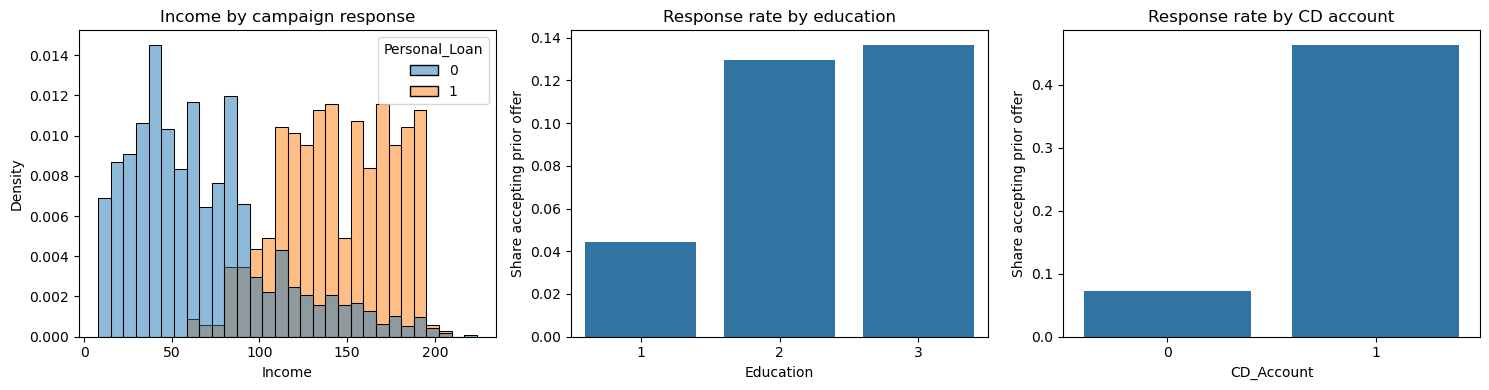

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(data=df, x="Income", hue=target, bins=30, stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Income by campaign response")
sns.barplot(data=df, x="Education", y=target, errorbar=None, ax=axes[1])
axes[1].set_title("Response rate by education")
axes[1].set_ylabel("Share accepting prior offer")
sns.barplot(data=df, x="CD_Account", y=target, errorbar=None, ax=axes[2])
axes[2].set_title("Response rate by CD account")
axes[2].set_ylabel("Share accepting prior offer")
fig.tight_layout()

In [6]:
response_by_group = pd.DataFrame({
    "Income band": pd.cut(df["Income"], bins=[0, 50, 75, 100, 150, np.inf],
                          labels=["≤50k", "50–75k", "75–100k", "100–150k", ">150k"]),
    "Education": df["Education"].map({1: "Undergraduate", 2: "Graduate", 3: "Advanced / professional"}),
    "CD account": df["CD_Account"].map({0: "No", 1: "Yes"}),
    "Accepted": df[target],
})
for feature in ["Income band", "Education", "CD account"]:
    print()
    print(f"Acceptance rate by {feature.lower()}")
    display(response_by_group.groupby(feature, observed=False)["Accepted"].agg(["size", "mean"]).rename(columns={"size": "customers", "mean": "acceptance_rate"}).style.format({"acceptance_rate": "{:.1%}"}))


Acceptance rate by income band


,customers,acceptance_rate
Income band,,
≤50k,1914,0.0%
50–75k,1044,0.7%
75–100k,830,4.2%
100–150k,770,28.6%
>150k,442,49.3%



Acceptance rate by education


,customers,acceptance_rate
Education,,
Advanced / professional,1501,13.7%
Graduate,1403,13.0%
Undergraduate,2096,4.4%



Acceptance rate by cd account


,customers,acceptance_rate
CD account,,
No,4698,7.2%
Yes,302,46.4%


### Reading the exploration

The plots and tables are descriptive associations in this historical dataset. They identify campaign segments worth discussing or testing; they do not show that income, education, or account ownership causes acceptance.

## 4. Prepare predictors and hold out a test set

`ID` and `ZIPCode` are excluded as identifiers/location proxies. `Experience` is excluded because it is strongly correlated with `Age`. Mortgage amount and a separate mortgage indicator are retained. The target is never included in the predictors.

In [7]:
model_df = df.copy()
model_df["Has_Mortgage"] = (model_df["Mortgage"] > 0).astype(int)
X = model_df.drop(columns=["ID", "ZIPCode", "Experience", "Personal_Loan"])
y = model_df[target].astype(int)

# One-hot encode nominal/binary fields; align columns after splitting to keep a reusable schema.
X = pd.get_dummies(
    X,
    columns=["Education", "Securities_Account", "CD_Account", "Online", "CreditCard", "Has_Mortgage"],
    drop_first=True,
    dtype=float,
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Training rows: {len(X_train):,}; test rows held back until final evaluation: {len(X_test):,}")
print("Training positive rate:", f"{y_train.mean():.1%}")
print("Test positive rate:", f"{y_test.mean():.1%}")
print("Model features:", ", ".join(X.columns))

Training rows: 4,000; test rows held back until final evaluation: 1,000
Training positive rate: 9.6%
Test positive rate: 9.6%
Model features: Age, Income, Family, CCAvg, Mortgage, Education_2, Education_3, Securities_Account_1, CD_Account_1, Online_1, CreditCard_1, Has_Mortgage_1


## 5. Model selection process

We compare four interpretable decision tree approaches, preserving the modeling progression from the analysis:

- **Baseline:** default tree to establish a reference and inspect overfitting.
- **Pre-pruned, precision focused:** choose tree size using cross-validated precision.
- **Pre-pruned, recall focused:** choose tree size using cross-validated recall.
- **Cost complexity pruned:** select `ccp_alpha` using cross-validated precision.

All tuning below uses only the training split with stratified 5-fold cross validation. We do not use the test split to choose parameters or a winner. Precision measures how many predicted responders accepted previously; recall measures how many historical responders are found. Which tradeoff is useful depends on campaign capacity and contact cost.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"precision": "precision", "recall": "recall", "f1": "f1"}

baseline = DecisionTreeClassifier(random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)

common_grid = {
    "max_depth": [2, 4, 6, 8, 10, None],
    "min_samples_leaf": [1, 5, 10, 20],
    "min_samples_split": [2, 10, 20],
}
precision_search = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE), common_grid,
    scoring=scoring, refit="precision", cv=cv, n_jobs=-1,
)
recall_search = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE), common_grid,
    scoring=scoring, refit="recall", cv=cv, n_jobs=-1,
)
precision_search.fit(X_train, y_train)
recall_search.fit(X_train, y_train)

# Use a fixed alpha grid so validation folds do not influence candidate generation.
alpha_candidates = np.linspace(0.0, 0.01, 41)
pruning_search = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    {"ccp_alpha": alpha_candidates}, scoring=scoring, refit="precision", cv=cv, n_jobs=-1,
)
pruning_search.fit(X_train, y_train)

models = {
    "Baseline tree": baseline,
    "Pre-pruned (precision CV)": precision_search.best_estimator_,
    "Pre-pruned (recall CV)": recall_search.best_estimator_,
    "Cost complexity pruned (precision CV)": pruning_search.best_estimator_,
}
print("Precision focused CV parameters:", precision_search.best_params_)
print("Recall focused CV parameters:", recall_search.best_params_)
print("Cost complexity CV alpha:", pruning_search.best_params_["ccp_alpha"])

Precision focused CV parameters: {'max_depth': 6, 'min_samples_leaf': 1, 'min_samples_split': 2}
Recall focused CV parameters: {'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2}
Cost complexity CV alpha: 0.003


### Compare cross-validation results

In [9]:
baseline_cv = cross_validate(
    DecisionTreeClassifier(random_state=RANDOM_STATE), X_train, y_train,
    scoring=scoring, cv=cv, n_jobs=-1,
)
cv_results = pd.DataFrame({
    "Baseline tree": {
        "CV precision": baseline_cv["test_precision"].mean(),
        "CV recall": baseline_cv["test_recall"].mean(),
        "CV F1": baseline_cv["test_f1"].mean(),
        "Selected parameters": "Default settings",
    },
    "Pre-pruned (precision CV)": {
        "CV precision": precision_search.cv_results_["mean_test_precision"][precision_search.best_index_],
        "CV recall": precision_search.cv_results_["mean_test_recall"][precision_search.best_index_],
        "CV F1": precision_search.cv_results_["mean_test_f1"][precision_search.best_index_],
        "Selected parameters": str(precision_search.best_params_),
    },
    "Pre-pruned (recall CV)": {
        "CV precision": recall_search.cv_results_["mean_test_precision"][recall_search.best_index_],
        "CV recall": recall_search.cv_results_["mean_test_recall"][recall_search.best_index_],
        "CV F1": recall_search.cv_results_["mean_test_f1"][recall_search.best_index_],
        "Selected parameters": str(recall_search.best_params_),
    },
    "Cost complexity pruned (precision CV)": {
        "CV precision": pruning_search.cv_results_["mean_test_precision"][pruning_search.best_index_],
        "CV recall": pruning_search.cv_results_["mean_test_recall"][pruning_search.best_index_],
        "CV F1": pruning_search.cv_results_["mean_test_f1"][pruning_search.best_index_],
        "Selected parameters": str(pruning_search.best_params_),
    },
}).T
cv_results

,CV precision,CV recall,CV F1,Selected parameters
Baseline tree,0.911715,0.882946,0.896767,Default settings
Pre-pruned (precision CV),0.966508,0.877751,0.919402,"{'max_depth': 6, 'min_samples_leaf': 1, 'min_s..."
Pre-pruned (recall CV),0.939847,0.89337,0.914151,"{'max_depth': 10, 'min_samples_leaf': 5, 'min_..."
Cost complexity pruned (precision CV),0.978313,0.789166,0.873397,{'ccp_alpha': np.float64(0.003)}


The CV table reports precision, recall, and F1 for all four candidates. Choose the metric that matches your campaign goal in the next cell. For example, precision favors a smaller list with a higher share of likely responders; recall finds more of the historical responders; F1 balances precision and recall. The held-out test results come after selection and are not used to choose the model.

In [10]:
# Choose what "best" means for your campaign. Options: "precision", "recall", or "f1".
SELECTION_METRIC = "precision"

metric_column = f"CV {SELECTION_METRIC}"
if metric_column not in cv_results.columns:
    raise ValueError("SELECTION_METRIC must be one of: 'precision', 'recall', 'f1'.")

# Choose the highest cross-validated score for the metric you selected.
selected_name = cv_results[metric_column].astype(float).idxmax()
final_model = models[selected_name]
selected_cv_score = float(cv_results.loc[selected_name, metric_column])
print("Selection metric:", SELECTION_METRIC)
print("Selected model using training-only cross validation:", selected_name)
print(f"Mean cross-validated {SELECTION_METRIC}: {selected_cv_score:.3f}")
print("To compare a different definition of best, change SELECTION_METRIC and run all cells again.")

Selection metric: precision
Selected model using training-only cross validation: Cost complexity pruned (precision CV)
Mean cross-validated precision: 0.978
To compare a different definition of best, change SELECTION_METRIC and run all cells again.


## 6. Final holdout evaluation

This is the first and only section that evaluates the held-out test set. The test results below are a final estimate for the model selected without test data.

In [11]:
def evaluate(model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    return {
        "Accuracy": accuracy_score(y_eval, predictions),
        "Precision": precision_score(y_eval, predictions, zero_division=0),
        "Recall": recall_score(y_eval, predictions, zero_division=0),
        "F1": f1_score(y_eval, predictions, zero_division=0),
    }

# Evaluate the predeclared model set once, for transparent comparison; selection remains CV-based.
test_results = pd.DataFrame({name: evaluate(model, X_test, y_test) for name, model in models.items()}).T
test_results.style.format("{:.3f}")

,Accuracy,Precision,Recall,F1
Baseline tree,0.979,0.857,0.938,0.896
Pre-pruned (precision CV),0.983,0.876,0.958,0.915
Pre-pruned (recall CV),0.975,0.809,0.969,0.882
Cost complexity pruned (precision CV),0.986,0.966,0.885,0.924


                precision    recall  f1-score   support

Did not accept       0.99      1.00      0.99       904
      Accepted       0.97      0.89      0.92        96

      accuracy                           0.99      1000
     macro avg       0.98      0.94      0.96      1000
  weighted avg       0.99      0.99      0.99      1000



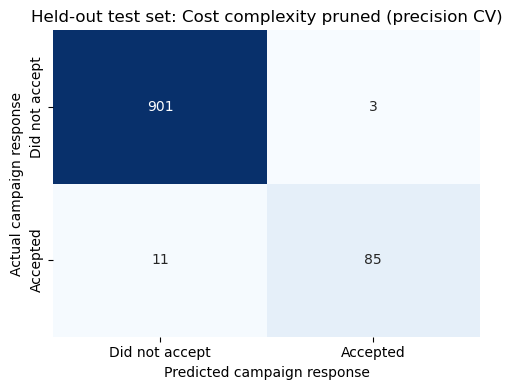

In [12]:
test_predictions = final_model.predict(X_test)
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Did not accept", "Accepted"],
            yticklabels=["Did not accept", "Accepted"], ax=ax)
ax.set_xlabel("Predicted campaign response")
ax.set_ylabel("Actual campaign response")
ax.set_title(f"Held-out test set: {selected_name}")
fig.tight_layout()
print(classification_report(y_test, test_predictions, target_names=["Did not accept", "Accepted"], zero_division=0))

## 7. Explain the selected tree

Features with nonzero tree importance, highest first:
Income         0.488211
Family         0.212727
Education_2    0.158962
Education_3    0.140100


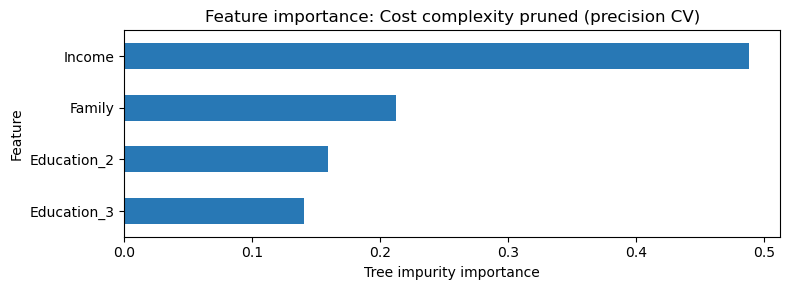

In [13]:
importance = pd.Series(final_model.feature_importances_, index=X_train.columns).sort_values()
importance = importance[importance > 0]
ax = importance.plot.barh(figsize=(8, max(3, 0.35 * len(importance))), color="#2878B5")
ax.set_title(f"Feature importance: {selected_name}")
ax.set_xlabel("Tree impurity importance")
ax.set_ylabel("Feature")
plt.tight_layout()
print("Features with nonzero tree importance, highest first:")
print(importance.sort_values(ascending=False).to_string())

## 8. Findings and limitations

The tables and plots above are generated from this run. Use the cross-validation table to describe the model-selection process and the held-out table for final metrics. The selected model depends on `SELECTION_METRIC` near the end of the model-selection section. Avoid copying metric values into prose; those values can change if the data or modeling choices change.

### Interpretation
- The model estimates past campaign acceptance patterns, not whether someone should receive or qualify for a loan.
- Precision may help prioritize a limited outreach list, while recall may matter when missing a likely responder is costly. A real campaign should set this tradeoff using contact cost and capacity.
- Decision tree feature importance describes how this fitted tree split the available data. It does not establish causality or customer suitability.
- The data are historical and may not represent current customers or future campaigns. Validate on a later campaign before operational use.

### Next steps before deployment
Use a time-based validation set from a later campaign, compare against a simple response-rate baseline, assess calibration and business lift, monitor drift and segment performance, and have appropriate stakeholders review the data and intended use. Treat any deployment as campaign decision support with human oversight.